# Laboratorio 3 - La tarea de clasificación

*Presentado por:*
- Shaiel Jiménez - 202323846
- Juan Esteban Triviño - 202315338

*ISIS2611 - Aprendizaje de Máquina / Sección 5*

*Profesor: Rubén Manrique*

**Contenido**

1. [Introducción](#introduccion)
2. [Configuración del entorno](#entorno)
3. [Actividad 1 — Exploración de los datos](#actividad1)
4. [Actividad 2 — Limpieza y preparación](#actividad2)
5. [Actividad 3 — Regresión logística](#actividad3)
6. [Actividad 4 — Árboles de decisión](#actividad4)
7. [Actividad 5 — Random Forest](#actividad5)
8. [Actividad 6 — Balanceo de clases (Restaurante(<20))](#actividad6)
9. [Actividad 7 — Tabla comparativa](#actividad7)
10. [Actividad 8 — Variables más relevantes](#actividad8)
11. [Actividad 10 — Predicciones sobre los datos de prueba](#actividad10)
12. [Análisis de resultados](#analisis)
13. [Uso de herramientas de IA generativa](#iag)

## <a id="introduccion"></a> Introducción

*(Por completar: contexto del caso Ruta Alpes, objetivo, resumen de decisiones metodológicas.)*

## <a id="entorno"></a> Configuración del entorno

In [80]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score,
)

# SMOTE y Pipeline de imblearn (Actividad 6)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [81]:
DATA_DIR = Path("data/raw")
RUTA_DATOS = DATA_DIR / "Lab3_Datos.xlsx"
RUTA_PRUEBA = DATA_DIR / "Lab3_datos_Prueba.xlsx"
RUTA_DICCIONARIO = DATA_DIR / "Lab3_diccionario_Datos.xlsx"

# Mismos folds para todos los modelos
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Archivos de datos:", [p.name for p in DATA_DIR.glob("*.xlsx")])

Archivos de datos: ['Lab3_Datos.xlsx', 'Lab3_diccionario_Datos.xlsx', 'Lab3_datos_Prueba.xlsx']


## <a id="actividad1"></a> Actividad 1 — Exploración de los datos

### 1.1 Carga y estructura

Se cargan los datos de entrenamiento, los de prueba (que no traen la etiqueta) y el diccionario
de variables, y se revisa que sean coherentes entre sí.

In [82]:
df = pd.read_excel(RUTA_DATOS)
prueba = pd.read_excel(RUTA_PRUEBA)
diccionario = pd.read_excel(RUTA_DICCIONARIO)

print(f"Entrenamiento: {df.shape} | Prueba: {prueba.shape} | Diccionario: {diccionario.shape}")
pd.DataFrame({"tipo": df.dtypes, "valores_unicos": df.nunique()})

Entrenamiento: (12664, 26) | Prueba: (20, 25) | Diccionario: (26, 3)


,tipo,valores_unicos
destino,str,3
acompanante,str,4
clima,str,3
temperatura,int64,3
hora,str,5
cupon,str,5
vigencia_cupon,str,2
genero,str,2
edad,str,8
estado_civil,str,5


In [83]:
cols_dic = set(diccionario["Variable"])
print("Columnas del diccionario que faltan en los datos:", cols_dic - set(df.columns))
print("Columnas de los datos que no están en el diccionario:", set(df.columns) - cols_dic)
print("Diferencia entre entrenamiento y prueba:", set(df.columns) ^ set(prueba.columns))

Columnas del diccionario que faltan en los datos: set()
Columnas de los datos que no están en el diccionario: set()
Diferencia entre entrenamiento y prueba: {'acepta_cupon'}


**Hallazgos.** Los datos coinciden con el diccionario y el archivo de prueba solo se diferencia
en `acepta_cupon`, que es justamente lo que hay que predecir. De las 26 variables solo
`temperatura` es numérica; el resto son categóricas, nominales u ordinales, y entre ellas `edad`
llama la atención porque mezcla números con textos como "menor de 21" y "50 o más". Por último,
`tiempo_cupon_mayor_5min` tiene un único valor, así que no sirve para distinguir nada (se
confirma en 1.7).

### 1.2 Valores nulos

Antes de decidir cómo tratar los faltantes conviene ver cuántos hay, en qué columnas y si
siguen algún patrón.

In [84]:
nulos = df.isna().sum()
tabla_nulos = pd.DataFrame({"nulos": nulos, "%": (nulos / len(df) * 100).round(2)})
tabla_nulos[tabla_nulos["nulos"] > 0]

,nulos,%
vehiculo,12556,99.15
frecuencia_bar,107,0.84
frecuencia_cafeteria,217,1.71
frecuencia_comida_para_llevar,151,1.19
frecuencia_restaurante_menos_20,130,1.03
frecuencia_restaurante_20_a_50,189,1.49


In [85]:
print("Nulos en el archivo de prueba:", prueba.isna().sum()[lambda s: s > 0].to_dict())

# Los nulos de frecuencia_* ¿son del conductor o del escenario?
perfil = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso"]
frec = [c for c in df.columns if c.startswith("frecuencia_")]
print(f"Perfiles distintos de conductor: {df[perfil].drop_duplicates().shape[0]} en {len(df)} filas")

por_perfil = df.assign(nulo=df[frec].isna().any(axis=1)).groupby(perfil)["nulo"].mean()
print(f"Perfiles con nulos en frecuencia_*: {(por_perfil > 0).sum()} | con nulos en todas sus filas: {(por_perfil == 1).sum()}")

Nulos en el archivo de prueba: {'vehiculo': 20}
Perfiles distintos de conductor: 519 en 12664 filas
Perfiles con nulos en frecuencia_*: 33 | con nulos en todas sus filas: 29


**Hallazgos y decisiones.**

- `vehiculo` está vacía en el 99% de las filas y siempre en la prueba, así que no hay
  información que recuperar: se elimina.
- Las cinco variables `frecuencia_*` tienen entre 0.8% y 1.7% de nulos. Casi siempre faltan en
  todas las filas del mismo conductor, es decir que no son errores aleatorios de un escenario
  sino preguntas que esa persona no contestó. Son pocos datos, por lo que se imputan con la
  moda y no se eliminan filas. La imputación va dentro del pipeline para que la moda se calcule
  solo con los datos de entrenamiento y no haya fuga de datos.
- Hay solo 519 perfiles de conductor para más de 12 mil filas: cada persona aparece en varios
  escenarios. Esto puede afectar la partición train/test y se revisa en 1.5.

### 1.3 Subconjuntos por tipo de cupón

El enunciado pide un modelo para cada uno de los cupones "Cafetería" y "Restaurante(<20)". Se
modelan por separado porque lo que lleva a aceptar un café no tiene por qué ser lo mismo que
lleva a aceptar un restaurante, y así además se pueden comparar los dos casos más adelante.

In [86]:
df["cupon"].value_counts().to_frame("filas")

,filas
cupon,
Cafetería,3986
Restaurante(<20),2776
Comida para llevar,2393
Bar,2017
Restaurante(20-50),1492


In [87]:
cafe = df[df["cupon"] == "Cafetería"].copy()
rest = df[df["cupon"] == "Restaurante(<20)"].copy()

print(f"Cafetería: {len(cafe)} | Restaurante(<20): {len(rest)} | Total: {len(cafe) + len(rest)} ({(len(cafe) + len(rest)) / len(df):.1%} del archivo)")
print("Cupones en la prueba:", prueba["cupon"].value_counts().to_dict())

Cafetería: 3986 | Restaurante(<20): 2776 | Total: 6762 (53.4% del archivo)
Cupones en la prueba: {'Cafetería': 10, 'Restaurante(<20)': 10}


**Hallazgos.** Los dos subconjuntos suman 6762 filas (53.4% del archivo); las otras 5902, de
los demás cupones, no se usan. Hay datos suficientes en ambos para separar un conjunto de
prueba y hacer validación cruzada. En el archivo de prueba hay solo 10 filas de cada cupón, por
lo que ese archivo sirve para generar las predicciones finales pero no para elegir modelos.
Dentro de cada subconjunto `cupon` es constante, así que junto con `tiempo_cupon_mayor_5min`
se elimina en la limpieza.

### 1.4 Distribución de la variable objetivo

Se mira cuántos conductores aceptan y cuántos rechazan el cupón en cada subconjunto, porque de
eso depende qué métricas tienen sentido para evaluar los modelos.

In [88]:
dist = pd.concat({"Cafetería": cafe["acepta_cupon"], "Restaurante(<20)": rest["acepta_cupon"]}, names=["cupon"])
dist = dist.groupby("cupon").value_counts().to_frame("filas")
dist["%"] = (dist["filas"] / dist.groupby("cupon")["filas"].transform("sum") * 100).round(1)
dist

filas     %
cupon            acepta_cupon             
Cafetería        No             1997  50.1
                 Sí             1989  49.9
Restaurante(<20) Sí             1962  70.7
                 No              814  29.3

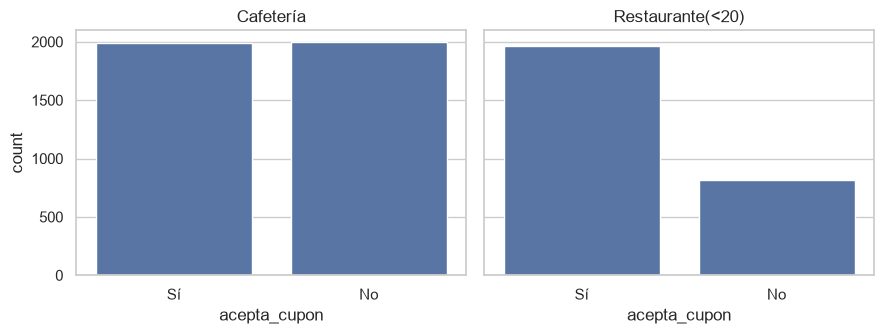

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, (nombre, datos) in zip(axes, [("Cafetería", cafe), ("Restaurante(<20)", rest)]):
    sns.countplot(data=datos, x="acepta_cupon", order=["Sí", "No"], ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("acepta_cupon")
plt.tight_layout()
plt.show()

**Hallazgos.** En **Cafetería** las clases están prácticamente parejas (49.9% acepta, 50.1%
rechaza), así que no hay desbalance. En **Restaurante(<20)** el 70.7% acepta y solo el 29.3%
rechaza, por lo que la clase minoritaria es el rechazo ("No"), y es la que más importa no
perder de vista.

Este desbalance hace que la exactitud engañe: un modelo que siempre responda "Sí" acertaría el
70.7% de las veces en Restaurante, sin detectar un solo rechazo. Por eso, además de la
exactitud, se reportan precisión, recall y F1 de cada clase, y se usa el **F1 macro** (promedio
del F1 de las dos clases) para elegir hiperparámetros en las búsquedas. Para que la proporción
de clases se conserve en la partición y en cada fold, ambas se hacen de forma estratificada.

### 1.5 Duplicados y conductores repetidos

Se revisan dos cosas: las filas repetidas, y si un mismo conductor aparece en varios escenarios,
algo que importa para armar los conjuntos de entrenamiento y prueba.

In [90]:
features = [c for c in df.columns if c != "acepta_cupon"]

resumen = {}
for nombre, datos in [("Cafetería", cafe), ("Restaurante(<20)", rest)]:
    grupos = datos.groupby(features, dropna=False)["acepta_cupon"].agg(["nunique", "size"])
    resumen[nombre] = {
        "filas": len(datos),
        "duplicadas exactas": datos.duplicated().sum(),
        "grupos con mismas características y etiquetas distintas": (grupos["nunique"] > 1).sum(),
    }
pd.DataFrame(resumen)

,Cafetería,Restaurante(<20)
filas,3986,2776
duplicadas exactas,7,7
grupos con mismas características y etiquetas distintas,4,3


In [91]:
# El archivo no trae identificador de conductor: se aproxima con las variables que describen
# a la persona (perfil demográfico y hábitos de consumo), que no cambian entre escenarios.
perfil = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso"]
frec = [c for c in df.columns if c.startswith("frecuencia_")]

def clave_conductor(d):
    return d[perfil + frec].fillna("NA").astype(str).agg("|".join, axis=1)

for d in (cafe, rest, prueba):
    d["conductor"] = clave_conductor(d)

for nombre, datos in [("Cafetería", cafe), ("Restaurante(<20)", rest)]:
    escenarios = datos["conductor"].value_counts()
    tr, te = train_test_split(datos, test_size=0.25, stratify=datos["acepta_cupon"], random_state=RANDOM_STATE)
    print(f"{nombre}: {len(escenarios)} conductores, {escenarios.median():.0f} escenarios por conductor (mediana), máximo {escenarios.max()}")
    print(f"   filas de test cuyo conductor aparece en train: {te['conductor'].isin(tr['conductor']).mean():.1%}")

conocidos = prueba["conductor"].isin(pd.concat([cafe["conductor"], rest["conductor"]]))
print(f"Archivo de prueba: {conocidos.sum()} de {len(prueba)} filas son de conductores presentes en el entrenamiento")

Cafetería: 565 conductores, 7 escenarios por conductor (mediana), máximo 28
   filas de test cuyo conductor aparece en train: 99.7%
Restaurante(<20): 567 conductores, 5 escenarios por conductor (mediana), máximo 26
   filas de test cuyo conductor aparece en train: 98.0%
Archivo de prueba: 20 de 20 filas son de conductores presentes en el entrenamiento


**Hallazgos.** Hay 7 filas duplicadas exactas en cada subconjunto, que se eliminan antes de
partir los datos para que una fila no quede en train y su copia en test. También hay unos pocos
grupos de escenarios idénticos con respuestas distintas (4 en Cafetería y 3 en Restaurante);
no se tocan, porque son ruido real: dos conductores con las mismas características pueden
decidir distinto, y eso explica por qué ningún modelo va a llegar al 100%.

Los datos no son independientes: el conjunto original viene de una encuesta en la que cada
persona respondió varios escenarios, pero no incluye un identificador de quién es quién. Como
aproximación se agrupan las filas que comparten las doce variables que describen a la persona,
lo que da unos 565 conductores, con mediana de 5 a 7 escenarios cada uno. Esta clave es un
supuesto nuestro, no un dato: dos personas con exactamente el mismo perfil quedarían en un solo
grupo, lo cual es el error más seguro para lo que se necesita (agrupa de más, no de menos).

Con una partición aleatoria casi todas las filas de test pertenecen a conductores que el modelo
ya vio en entrenamiento (98% a 99.7%). Lo mismo ocurre con las 20 filas del archivo de prueba,
así que partir de forma aleatoria y estratificada es coherente con el uso que se evalúa. Aun
así, esto puede hacer que las métricas salgan más optimistas de lo que serían con conductores
nuevos; por eso, con los modelos finales, se compara el desempeño con folds agrupados por
conductor y se discute en el análisis de limitaciones.

### 1.6 Consistencia de las categorías

Se revisa que cada variable tenga valores bien escritos y coherentes con el diccionario, y que
las columnas no se contradigan entre sí.

In [92]:
categoricas = [c for c in df.columns if c != "temperatura"]
tabla_valores = pd.DataFrame({
    "n_valores": [df[c].nunique() for c in categoricas],
    "valores": [
        "25 categorías (coinciden con el diccionario)" if c == "ocupacion"
        else ", ".join(df[c].dropna().unique())
        for c in categoricas
    ],
}, index=categoricas)

espacios = sum((df[c].dropna() != df[c].dropna().str.strip()).sum() for c in categoricas)
print("Valores con espacios sobrantes:", espacios)
tabla_valores

Valores con espacios sobrantes: 0


,n_valores,valores
destino,3,"Sin lugar urgente, Casa, Trabajo"
acompanante,4,"Solo, Amigo(s), Hijo(s), Pareja"
clima,3,"Soleado, Lluvioso, Nevado"
hora,5,"2:00 p.m., 10:00 a.m., 6:00 p.m., 7:00 a.m., 1..."
cupon,5,"Restaurante(<20), Cafetería, Comida para lleva..."
vigencia_cupon,2,"1 día, 2 horas"
genero,2,"Femenino, Masculino"
edad,8,"21, 46, 26, 31, 41, 50 o más, 36, menor de 21"
estado_civil,5,"Unión libre, Soltero(a), Casado(a), Divorciado..."
tiene_hijos,2,"Sí, No"


In [93]:
# Relaciones que deberían cumplirse entre columnas
print("clima vs temperatura:")
print(pd.crosstab(df["clima"], df["temperatura"]), "\n")

complementarias = (df["misma_direccion"] != df["direccion_opuesta"]).all()
print("misma_direccion y direccion_opuesta siempre son opuestas:", complementarias)

anidadas = ((df["tiempo_cupon_mayor_25min"] == "Sí") <= (df["tiempo_cupon_mayor_15min"] == "Sí")).all()
print("Mayor de 25 min implica mayor de 15 min:", anidadas, "\n")

print("destino vs hora:")
print(pd.crosstab(df["destino"], df["hora"]), "\n")

print("Acompañante 'Hijo(s)' sin tener hijos:", ((df["acompanante"] == "Hijo(s)") & (df["tiene_hijos"] == "No")).sum())

clima vs temperatura:
temperatura    30    55    80
clima                        
Lluvioso        0  1208     0
Nevado       1404     0     0
Soleado       911  2628  6513 

misma_direccion y direccion_opuesta siempre son opuestas: True
Mayor de 25 min implica mayor de 15 min: True 

destino vs hora:
hora               10:00 a.m.  10:00 p.m.  2:00 p.m.  6:00 p.m.  7:00 a.m.
destino                                                                   
Casa                        0        1113          0       2120          0
Sin lugar urgente        2271         890       2005       1104          0
Trabajo                     0           0          0          0       3161 

Acompañante 'Hijo(s)' sin tener hijos: 17


**Hallazgos.** Los valores están bien escritos y coinciden con el diccionario, sin variantes ni
espacios sobrantes. La única diferencia de formato es `ingreso`: el diccionario escribe los
rangos sin espacios (`$12.500-$24.999`) y los datos con espacios (`$12.500 - $24.999`), así que
el orden de esa variable debe definirse con el texto de los datos. `edad` mezcla números
guardados como texto con "menor de 21" y "50 o más", por lo que se trata como ordinal con un
orden explícito y no como numérica.

Las relaciones entre columnas son coherentes: la nieve solo aparece a 30 °F y la lluvia a 55 °F,
el trabajo siempre es a las 7:00 a.m., y quien está a más de 25 minutos también está a más de
15. Dos cosas llaman la atención. `misma_direccion` y `direccion_opuesta` son exactamente
opuestas (nunca coinciden), es decir que una es el complemento de la otra; se deja solo
`misma_direccion`, porque dos columnas que se calculan una a partir de la otra causan
multicolinealidad perfecta en la regresión logística. Y hay 17 filas con acompañante "Hijo(s)"
y `tiene_hijos` en "No", que se conservan porque pueden ser niños que viajan con el conductor
sin ser sus hijos.

**Codificación que se usará en los pipelines.**
- *Ordinales (con orden explícito):* `hora`, `edad`, `educacion`, `ingreso` y las cinco
  `frecuencia_*`.
- *Binarias:* `genero`, `tiene_hijos`, `vigencia_cupon`, `tiempo_cupon_mayor_15min`,
  `tiempo_cupon_mayor_25min` y `misma_direccion`.
- *Nominales (one-hot):* `destino`, `acompanante`, `clima`, `estado_civil` y `ocupacion`.
- *Numérica:* `temperatura`.

Se encuentran además combinaciones poco comunes, como jubilados de 26 o 36 años o menores de 21
con pregrado, en 22 filas cada una (parecen ser un solo encuestado). No son imposibles, así que
se conservan.

### 1.7 Variables constantes o casi constantes

Una variable que casi no cambia no ayuda a distinguir entre quienes aceptan y quienes rechazan.
Se mide qué porcentaje de las filas tiene el valor más frecuente de cada variable, sin contar las
columnas que ya se decidió eliminar.

In [94]:
descartadas = ["vehiculo", "cupon", "direccion_opuesta"]
predictoras = [c for c in df.columns if c not in descartadas + ["acepta_cupon"]]

def dominancia(d):
    return d[predictoras].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)

tabla_dominancia = pd.DataFrame({"Cafetería (%)": dominancia(cafe), "Restaurante(<20) (%)": dominancia(rest)})
tabla_dominancia.sort_values("Cafetería (%)", ascending=False).round(1).head(6)

,Cafetería (%),Restaurante(<20) (%)
tiempo_cupon_mayor_5min,100.0,100.0
tiempo_cupon_mayor_25min,92.2,88.8
clima,86.8,80.4
misma_direccion,81.3,82.0
tiene_hijos,61.2,58.8
temperatura,60.1,56.4


In [95]:
# Categorías con muy pocas filas dentro de cada subconjunto
for nombre, datos in [("Cafetería", cafe), ("Restaurante(<20)", rest)]:
    conteos = pd.concat([datos[c].value_counts() for c in predictoras if c != "temperatura"])
    raras = conteos[conteos < 30]
    print(f"{nombre}: {len(raras)} categorías con menos de 30 filas ->", raras.to_dict())

Cafetería: 4 categorías con menos de 30 filas -> {'Bachillerato incompleto': 28, 'Producción': 28, 'Limpieza y Mantenimiento de Edificios': 11, 'Agricultura, Pesca y Silvicultura': 11}
Restaurante(<20): 6 categorías con menos de 30 filas -> {'Viudo(a)': 29, 'Bachillerato incompleto': 18, 'Instalación, Mantenimiento y Reparación': 27, 'Producción': 25, 'Limpieza y Mantenimiento de Edificios': 10, 'Agricultura, Pesca y Silvicultura': 7}


**Hallazgos.** `tiempo_cupon_mayor_5min` vale "Sí" en el 100% de las filas de los dos
subconjuntos, así que no distingue nada y se elimina. Las que le siguen en dominancia son
`tiempo_cupon_mayor_25min` (89% a 92% en "No"), `clima` (80% a 87% soleado) y `misma_direccion`
(unas 8 de cada 10 filas en "No"). Se conservan, porque que una variable sea poco variable no
significa que sea poco informativa: su efecto sobre la aceptación se mira en 1.8.

También hay categorías con muy pocas filas, sobre todo ocupaciones poco comunes (Producción,
Agricultura, Limpieza de edificios) y "Bachillerato incompleto". Casi siempre son una sola
persona repetida en varios escenarios, lo que puede llevar al modelo a aprender a esa persona en
lugar de un patrón general. No se agrupan por ahora; si aparece inestabilidad al modelar, se
controla con la regularización, con `min_samples_leaf` en los árboles o agrupando las categorías
infrecuentes en el codificador.

### 1.8 Relación de cada variable con la aceptación

Como casi todas las variables son categóricas, la correlación de Pearson no sirve. Se usa en su
lugar la **V de Cramér**, que mide la asociación entre dos variables categóricas en una escala de
0 (ninguna) a 1 (total), y luego se mira la tasa de aceptación por categoría en las variables
más asociadas. Este análisis es descriptivo: una asociación no implica que una variable cause la
aceptación.

In [96]:
from scipy.stats import chi2_contingency

def v_cramer(x, y):
    tabla = pd.crosstab(x, y)  # ignora las filas con nulos en x
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))

variables = [c for c in predictoras if c != "tiempo_cupon_mayor_5min"]  # esta es constante
tabla_v = pd.DataFrame({
    "Cafetería": [v_cramer(cafe[c], cafe["acepta_cupon"]) for c in variables],
    "Restaurante(<20)": [v_cramer(rest[c], rest["acepta_cupon"]) for c in variables],
}, index=variables)
tabla_v.sort_values("Cafetería", ascending=False).round(3)

,Cafetería,Restaurante(<20)
frecuencia_cafeteria,0.378,0.093
destino,0.185,0.237
hora,0.179,0.283
ocupacion,0.168,0.141
vigencia_cupon,0.151,0.267
acompanante,0.146,0.161
ingreso,0.125,0.112
edad,0.105,0.085
tiempo_cupon_mayor_15min,0.094,0.115
tiempo_cupon_mayor_25min,0.089,0.297


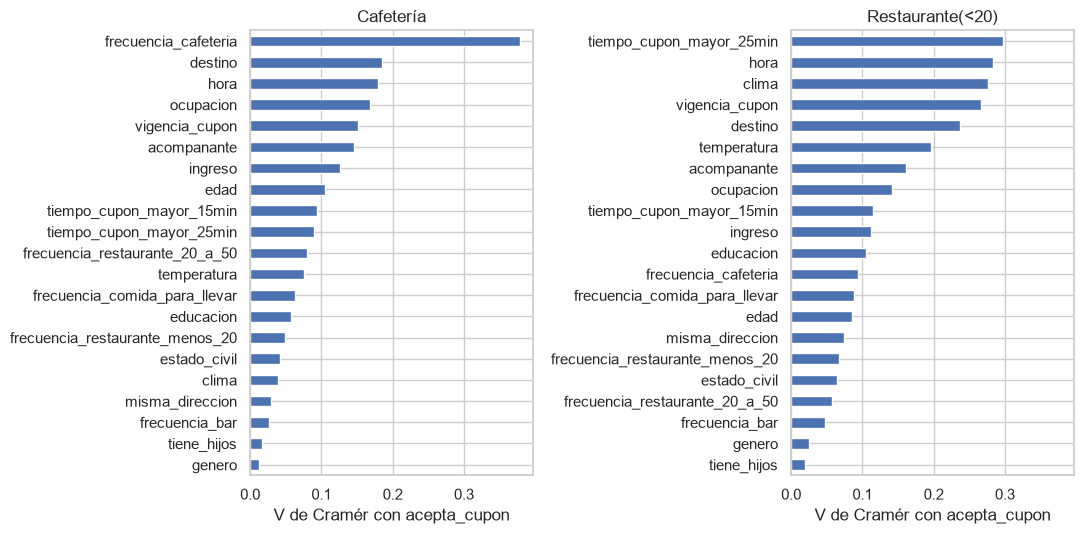

In [97]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharex=True)
for ax, nombre in zip(axes, ["Cafetería", "Restaurante(<20)"]):
    tabla_v[nombre].sort_values().plot.barh(ax=ax)
    ax.set_title(nombre)
    ax.set_xlabel("V de Cramér con acepta_cupon")
plt.tight_layout()
plt.show()

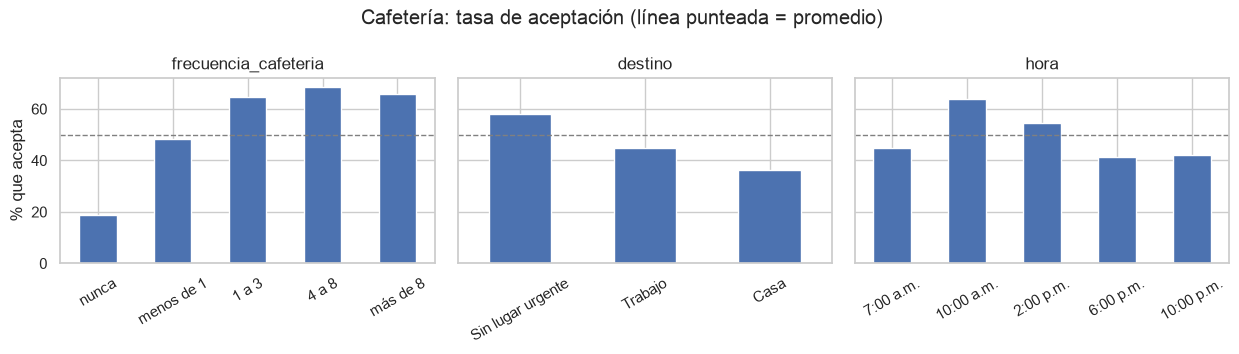

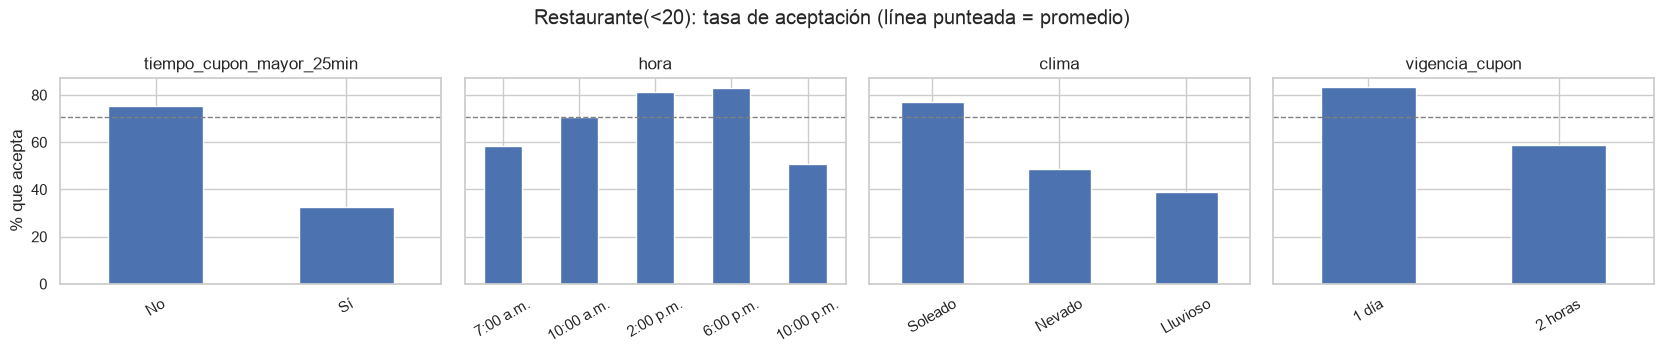

In [98]:
orden_frec = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
orden_hora = ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."]
ordenes = {"frecuencia_cafeteria": orden_frec, "hora": orden_hora}

def graficar_tasas(datos, columnas, titulo):
    fig, axes = plt.subplots(1, len(columnas), figsize=(4.2 * len(columnas), 3.6), sharey=True)
    for ax, col in zip(axes, columnas):
        tasa = (datos["acepta_cupon"] == "Sí").groupby(datos[col]).mean() * 100
        if col in ordenes:
            tasa = tasa.reindex(ordenes[col])
        else:
            tasa = tasa.sort_values(ascending=False)
        tasa.plot.bar(ax=ax)
        ax.axhline((datos["acepta_cupon"] == "Sí").mean() * 100, color="gray", linestyle="--", linewidth=1)
        ax.set_title(col)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=30)
    axes[0].set_ylabel("% que acepta")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

graficar_tasas(cafe, ["frecuencia_cafeteria", "destino", "hora"], "Cafetería: tasa de aceptación (línea punteada = promedio)")
graficar_tasas(rest, ["tiempo_cupon_mayor_25min", "hora", "clima", "vigencia_cupon"], "Restaurante(<20): tasa de aceptación (línea punteada = promedio)")

**Hallazgos.** Los dos cupones se explican por cosas distintas. En **Cafetería** pesa sobre todo
el hábito del conductor: `frecuencia_cafeteria` es la variable más asociada por mucha diferencia
(V ≈ 0.38): solo el 19% de quienes nunca van a cafeterías acepta, frente al 65% a 69% de quienes
van varias veces al mes. Le siguen el destino, la hora y la vigencia del cupón. En
**Restaurante(<20)** pesa más el contexto del viaje: la distancia (más de 25 minutos), la hora,
el clima, la vigencia y el destino tienen V entre 0.24 y 0.30, mientras que los hábitos del
conductor casi no importan.

Las variables menos asociadas en ambos casos son `genero`, `tiene_hijos` y `frecuencia_bar`. Las
variables demográficas `edad`, `ingreso` y `ocupacion` tienen una asociación pequeña pero no
nula, algo que se retoma en el análisis de sesgo.

Hay que leer estos números con cuidado por dos razones. Primero, `ocupacion` tiene 25 categorías
con pocas filas en varias de ellas, lo que infla artificialmente la V. Segundo, algunos efectos no
son monótonos: la aceptación por hora o por ingreso sube y baja en lugar de crecer de forma
pareja, lo que un árbol capta sin problema pero una regresión logística con codificación ordinal
no. Por eso, en la Actividad 3 se compara la codificación ordinal con one-hot para esas
variables, en lugar de decidirlo ahora. Ninguna variable se descarta todavía.

### 1.9 Redundancia entre predictoras

Además de la relación con el objetivo, interesa saber si algunas predictoras dicen casi lo mismo,
porque eso afecta la estabilidad de los coeficientes en la regresión logística. Se calcula la V de
Cramér entre todos los pares de predictoras, con los dos cupones juntos.

In [99]:
from itertools import combinations

ambos = pd.concat([cafe, rest])
matriz_v = pd.DataFrame(1.0, index=variables, columns=variables)
for a, b in combinations(variables, 2):
    matriz_v.loc[a, b] = matriz_v.loc[b, a] = v_cramer(ambos[a], ambos[b])

pares_v = matriz_v.where(np.triu(np.ones(matriz_v.shape), k=1).astype(bool)).stack()
top_pares = pares_v.sort_values(ascending=False).head(10).round(3)
top_pares.index = [f"{a} – {b}" for a, b in top_pares.index]
top_pares.to_frame("V de Cramér")

,V de Cramér
destino – hora,0.832
clima – temperatura,0.673
estado_civil – tiene_hijos,0.565
destino – misma_direccion,0.558
destino – acompanante,0.518
edad – tiene_hijos,0.494
hora – misma_direccion,0.410
destino – tiempo_cupon_mayor_25min,0.382
acompanante – misma_direccion,0.375
acompanante – tiene_hijos,0.362


In [100]:
# Variables de la persona (perfil y hábitos) frente a variables del escenario
persona = [c for c in variables if c in perfil or c in frec]
escenario = [c for c in variables if c not in persona]

print(f"V promedio entre variables de la persona:   {pares_v[[a in persona and b in persona for a, b in pares_v.index]].mean():.3f}")
print(f"V promedio entre persona y escenario:       {matriz_v.loc[persona, escenario].stack().mean():.3f}")
print(f"Pares con V >= 0.5: {(pares_v >= 0.5).sum()} | pares con V >= 0.3: {(pares_v >= 0.3).sum()}")

V promedio entre variables de la persona:   0.176
V promedio entre persona y escenario:       0.039
Pares con V >= 0.5: 5 | pares con V >= 0.3: 19


**Hallazgos.** Cinco pares superan 0.5 y ninguno se acerca a ser un duplicado. El más alto es
`destino` con `hora` (V ≈ 0.83), que es consecuencia del diseño de la encuesta: ir al trabajo
ocurre siempre a las 7:00 a.m., ir a casa solo en la tarde-noche, y "sin lugar urgente" a
cualquier hora menos las 7:00 a.m. Le sigue `clima` con `temperatura` (≈ 0.67): la nieve siempre
es a 30 °F y la lluvia a 55 °F, mientras que el día soleado se da con las tres temperaturas.
También hay relaciones esperables como `estado_civil` con `tiene_hijos` o `destino` con
`misma_direccion` (cuando no hay un lugar urgente, la dirección siempre es "No").

Las variables que describen a la persona casi no se relacionan con las del escenario (V promedio
de 0.04, frente a 0.18 entre las de la persona), lo que es coherente con escenarios asignados sin
tener en cuenta quién es el conductor. Dentro de las variables de la persona, el valor de V está
algo inflado porque hay solo unos 565 conductores distintos.

**Decisión.** No se elimina ninguna predictora por redundancia. Las superposiciones se deben al
diseño de la encuesta, y ambas variables de cada pareja aportan información propia (por ejemplo,
en Restaurante `clima` tiene V = 0.27 y `temperatura` 0.20). La colinealidad moderada que queda
se controla con la regularización de la regresión logística, y los árboles no se ven afectados
al predecir, aunque la importancia puede repartirse entre variables correlacionadas, algo que se
tendrá en cuenta al interpretarla en la Actividad 8.

En resumen, hay una columna redundante (`direccion_opuesta`, ya eliminada), parcialmente
solapadas `destino`/`hora` y `clima`/`temperatura`, y poco informativas `genero`, `tiene_hijos`
y `frecuencia_bar`, además de la constante `tiempo_cupon_mayor_5min`.

### 1.10 Contraste con el archivo de prueba

Las predicciones finales se hacen sobre `Lab3_datos_Prueba`, así que conviene confirmar que ese
archivo es compatible con los datos de entrenamiento antes de construir los modelos.

In [101]:
cols_prueba = [c for c in prueba.columns if c != "conductor"]  # 'conductor' es la clave creada en 1.5
print("Mismas columnas y en el mismo orden (sin la etiqueta):", cols_prueba == [c for c in df.columns if c != "acepta_cupon"])

nuevas = {c: set(prueba[c].dropna()) - set(df[c].dropna()) for c in cols_prueba}
print("Categorías de la prueba que no existen en entrenamiento:", {c: v for c, v in nuevas.items() if v})
print("Nulos en la prueba:", prueba[cols_prueba].isna().sum()[lambda s: s > 0].to_dict())
print("Filas duplicadas en la prueba:", prueba[cols_prueba].duplicated().sum())
print("Cupones en la prueba:", prueba["cupon"].value_counts().to_dict())

Mismas columnas y en el mismo orden (sin la etiqueta): True
Categorías de la prueba que no existen en entrenamiento: {}
Nulos en la prueba: {'vehiculo': 20}
Filas duplicadas en la prueba: 0
Cupones en la prueba: {'Cafetería': 10, 'Restaurante(<20)': 10}


**Hallazgos.** El archivo de prueba tiene las mismas columnas que el de entrenamiento (menos la
etiqueta), ninguna categoría nueva y ningún nulo aparte de `vehiculo`, que está vacía y se elimina.
Trae 10 filas de Cafetería y 10 de Restaurante(<20), sin duplicados. No se necesita ninguna
transformación especial: se aplica el mismo pipeline que se entrene y cada fila se predice con el
modelo de su cupón. Como el pipeline usa `handle_unknown="ignore"` en el codificador, tampoco
habría problema si en otro momento llegara una categoría nueva.

### 1.11 Síntesis de la exploración

La siguiente tabla resume lo encontrado, organizado por las dimensiones de calidad de datos, y
la decisión que se toma en cada caso. Estas decisiones se implementan en la Actividad 2.

| Dimensión | Hallazgo | Decisión |
|:---|:---|:---|
| **Completitud** | `vehiculo` tiene 99.15% de nulos | Se elimina |
| | `frecuencia_*` tiene entre 0.8% y 1.7% de nulos, por conductor | Imputar con la moda dentro del pipeline |
| **Unicidad** | 7 filas duplicadas exactas por cupón | Se eliminan antes de partir los datos |
| | 4 grupos (Cafetería) y 3 (Restaurante) con las mismas características y etiquetas distintas | Se conservan: es ruido real del problema |
| | Cada conductor aparece en varios escenarios (unos 565) | Partición estratificada, más una verificación con folds agrupados por conductor |
| **Consistencia** | `direccion_opuesta` es el complemento exacto de `misma_direccion` | Se elimina |
| | `ingreso` se escribe distinto en el diccionario y en los datos; `edad` mezcla texto y números | Orden ordinal explícito, con el texto de los datos |
| | Relaciones entre columnas (clima y temperatura, destino y hora, distancias) | Sin violaciones |
| **Validez** | Todos los valores están dentro del dominio del diccionario; `temperatura` solo toma 30, 55 y 80 | Sin acción |
| | `tiempo_cupon_mayor_5min` es constante | Se elimina |
| | 17 casos de "Hijo(s)" sin tener hijos y algunas combinaciones atípicas de edad con ocupación o educación | Se conservan, documentados |
| **Valores atípicos** | No hay variables continuas; hay categorías con menos de 30 filas (4 en Cafetería, 6 en Restaurante) | Se conservan; se controlan con regularización y `min_samples_leaf` |
| **Variable objetivo** | Cafetería 50/50; Restaurante 70.7% acepta y 29.3% rechaza | Partición y folds estratificados; F1 macro para elegir hiperparámetros |

De las 26 columnas originales quedan **21 predictoras** por cupón (se eliminan `vehiculo`, `cupon`,
`direccion_opuesta` y `tiempo_cupon_mayor_5min`, y `acepta_cupon` pasa a ser la variable objetivo).

**Lo que la exploración ya anticipa.** Cafetería parece depender sobre todo del hábito del
conductor (`frecuencia_cafeteria`), y Restaurante(<20) del contexto del viaje (distancia, hora,
clima, vigencia y destino). `genero`, `tiene_hijos` y `frecuencia_bar` casi no se relacionan con
la aceptación, y las variables demográficas (`edad`, `ingreso`, `ocupacion`) tienen una relación
pequeña pero no nula. Estas son hipótesis que los modelos deben confirmar o desmentir.